###    Fase 3 - Camanda Gold: perguntas de negócio + gráficos + Gold agregada ###

Projeto: Viagens a Serviço (Portal da Transparência - Gov.br)

Após limpeza e tipagem na camada SILVER, criaremos a camada GOLD (tabela e views) e responderemos as 7 perguntas de negócio. 

As 3 primeiras perguntas através de consulta SQL, tabelas e gráficos, com construição de uma camada Gold agregada (PostgreSQL - Tabelas e View)

Em seguida, repondendo mais 4 perguntas de negocio e elaboração de 3 gráficos.

Apresentarei as respostas para perguntas da seguite fomra: pergunta → consulta SQL → tabela → gráfico → conclusão

Como normativa usamos apenas as viagens realizadas, pois são estes dados que possibilitaram analisar o comportamento dos registros.

Antes de iniciar rodamos os arquivos 0_criar_banco.sql, 1_extrair.py e 2_transformar.py.
As credenciais desse projeto se encontram no arquivo .env


## BIBLIOTECAS E CONEXÃO ##

Realizaremos as consultas em SQL e devolveremos as tabelas em Pandas. Os números e datas já foram formatados na camada SILVER, formataremos apenas a exibição na tabela.

In [2]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from banco import conectar

# Ignora o aviso do Pandas sobre SQLAlchemy
warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")

# Mostra os números com 2 casas decimais nas tabelas
pd.set_option("display.float_format", "{:.2f}".format)


def consultar(sql):
    conexao = conectar()
    tabela = pd.read_sql(sql, conexao)
    conexao.close()
    return tabela

def formatar_numero(valor, casas=2):
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


# Teste de validação
teste = consultar("SELECT COUNT(*) AS viagens FROM silver_viagem")
print("Conexão OK. Viagens na camada Silver:", teste["viagens"][0])



Conexão OK. Viagens na camada Silver: 341860


### Bloco 1: As 3 Primeiras Perguntas (Camada Silver) ###

### Pergunta 1: Os 5 órgãos com maior custo total?

,orgao_superior,gasto_total_formatado
0,Ministério da Justiça e Segurança Pública,"R$ 486.933.121,65"
1,Ministério da Defesa,"R$ 156.070.304,49"
2,Ministério da Educação,"R$ 111.291.349,34"
3,Ministério do Meio Ambiente e Mudança do Clima,"R$ 49.697.710,16"
4,Ministério da Previdência Social,"R$ 40.417.309,06"


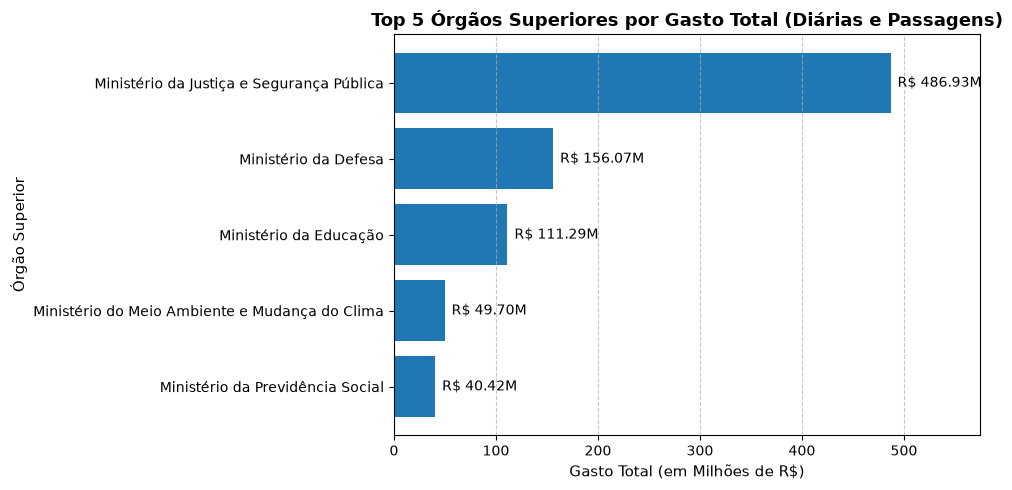

In [3]:
## Identifica quais ministérios ou órgãos concentram a maior parte das despesas com diárias e passagens.
## valor_total (diárias + passagens + outros gastos − devolução) -> calculado na camada SILVER

# 1. Consulta SQL direta na tabela silver_viagem (onde valor_total já está calculado)
sql_p1 = """
SELECT 
    nome_orgao_superior AS orgao_superior,
    ROUND(SUM(valor_total), 2) AS gasto_total
FROM silver_viagem
WHERE nome_orgao_superior IS NOT NULL
GROUP BY nome_orgao_superior
ORDER BY gasto_total DESC
LIMIT 5;
"""

# 2. Execução da consulta
df_p1 = consultar(sql_p1)

# Exibição da tabela com formatação monetária (R$ 1.234.567,89)
df_p1_formatado = df_p1.copy()
df_p1_formatado["gasto_total_formatado"] = df_p1_formatado["gasto_total"].apply(
    lambda x: f"R$ {x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
)
display(df_p1_formatado[["orgao_superior", "gasto_total_formatado"]])

# 3. Gráfico de Barras Horizontais (Valores em Milhões de R$)
plt.figure(figsize=(10, 5))

# Ordena de baixo para cima para o 1º colocado ficar no topo do gráfico
orgaos = df_p1["orgao_superior"][::-1]
gastos_milhoes = (df_p1["gasto_total"] / 1e6)[::-1]

barras = plt.barh(orgaos, gastos_milhoes, color="#1f77b4")
plt.title("Top 5 Órgãos Superiores por Gasto Total (Diárias e Passagens)", fontsize=13, weight="bold")
plt.xlabel("Gasto Total (em Milhões de R$)", fontsize=11)
plt.ylabel("Órgão Superior", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.7)

# Adiciona o rótulo de valor ao lado de cada barra
for barra in barras:
    largura = barra.get_width()
    plt.annotate(
        f"R$ {largura:.2f}M",
        xy=(largura, barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        ha="left",
        fontsize=10
    )

plt.xlim(0, max(gastos_milhoes) * 1.18)
plt.tight_layout()
plt.show()

### Conclusão — Pergunta 1: Top 5 Órgãos Superiores por Gasto Total

A análise da Camada Silver evidencia uma forte concentração orçamentária no Ministério da Justiça e Segurança Pública, que registrou R$ 486,93 milhões em despesas com diárias e passagens no período avaliado. Esse valor supera a soma de todos os outros quatro ministérios do Top 5 reunidos (Defesa, Educação, Meio Ambiente e Previdência Social). 

### Pergunta 2: Os 3 destinos com maior custo médio por viagem?

,destino,viagens,custo_medio
0,"Brasília/DF, Brasília/DF",283,27401.80
1,Genebra/Suíça,242,25469.22
2,Nova York/Estados Unidos da América,149,21214.19


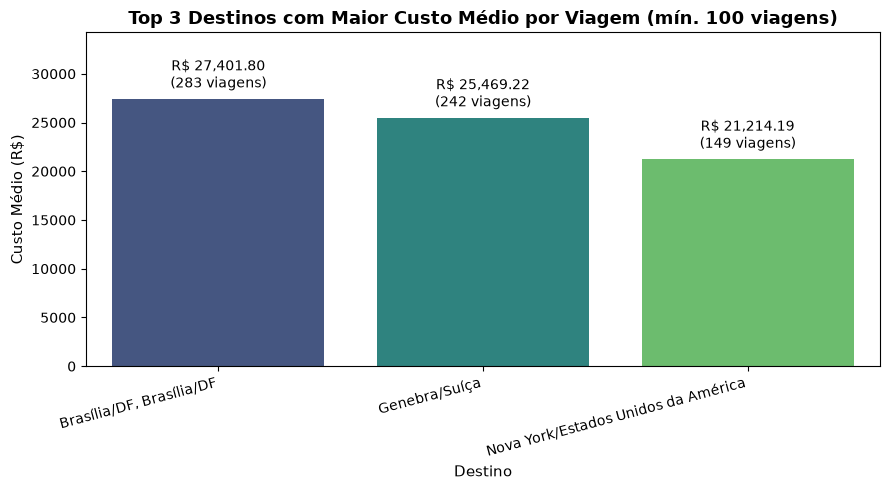

In [4]:
# --- Pergunta 2: Top 3 destinos com maior custo médio por viagem (mínimo 100 viagens realizadas) ---

query_p2 = """
SELECT 
    destinos AS destino,
    COUNT(*) AS viagens,
    ROUND(AVG(valor_total), 2) AS custo_medio
FROM silver_viagem
WHERE situacao = 'Realizada'
GROUP BY destinos
HAVING COUNT(*) >= 100
ORDER BY custo_medio DESC
LIMIT 3;
"""

df_p2 = consultar(query_p2)

# 1. Exibição da tabela formatada
display(df_p2)

# 2. Gráfico de Colunas
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=df_p2, 
    x="destino", 
    y="custo_medio", 
    hue="destino", 
    palette="viridis", 
    legend=False
)

plt.title("Top 3 Destinos com Maior Custo Médio por Viagem (mín. 100 viagens)", fontsize=13, weight="bold")
plt.xlabel("Destino", fontsize=11)
plt.ylabel("Custo Médio (R$)", fontsize=11)

# Rótulos sobre as colunas: Custo Médio e Quantidade de Viagens
for p, (_, row) in zip(ax.patches, df_p2.iterrows()):
    altura = p.get_height()
    ax.annotate(
        f"R$ {altura:,.2f}\n({int(row['viagens']):,} viagens)",
        (p.get_x() + p.get_width() / 2.0, altura),
        va="bottom",
        ha="center",
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=10
    )

# Margem superior no eixo Y para os rótulos não encostarem na borda
plt.ylim(0, df_p2["custo_medio"].max() * 1.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


### Conclusão — Pergunta 2: Top 3 Destinos com Maior Custo Médio por Viagem

Com o corte de significância (HAVING COUNT(*) >= 100), o ranking evidencia que o alto custo médio concentra-se em missões internacionais de longa permanência (Genebra e Nova York) e em deslocamentos para a capital federal. Esse resultado comprova que viagens recorrentes a centros diplomáticos globais e à sede do governo demandam planejamento orçamentário prévio em passagens e diárias para mitigar despesas elevadas.


### Pergunta 3: A viagem de maior duração e seu custo total?

Viagem de Maior Duração:


,id_viagem,cargo,nome_orgao_superior,data_inicio,data_fim,duracao_dias,valor_total_formatado
0,0000000000020699856,TECNICO DO SEGURO SOCIAL,Ministério da Previdência Social,13/01/2025,31/01/2026,384,"R$ 0,00"


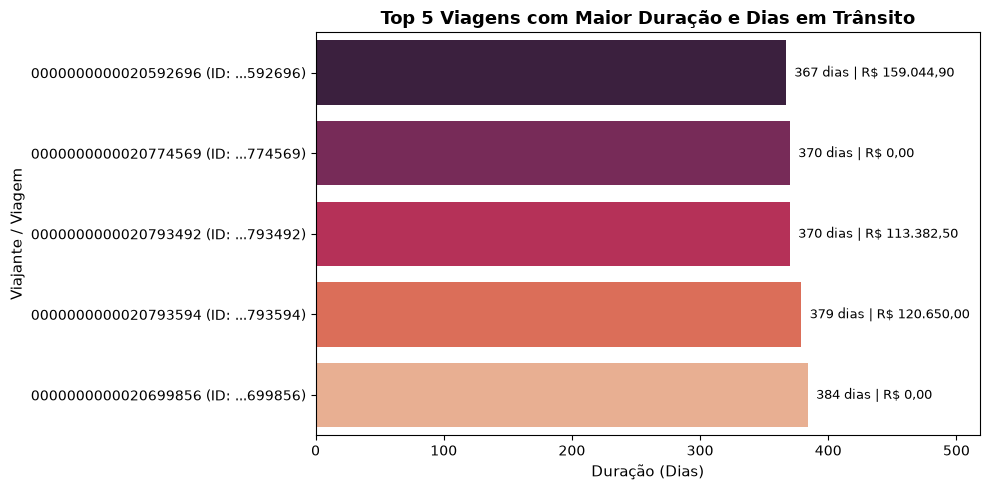

In [12]:
# --- Pergunta 3: A viagem de maior duração e seu custo total ---

# 1. Consulta SQL no PostgreSQL (traz as viagens mais longas)
sql_p3 = """
SELECT 
    id_viagem,
    cargo,
    nome_orgao_superior,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC
LIMIT 5;
"""

# 2. Leitura com a função auxiliar consultar() retornando um DataFrame Pandas
df_p3_comp = consultar(sql_p3)

# 3. Tratamento dos dados com Pandas
# Converte datas para string no padrão brasileiro DD/MM/AAAA
df_p3_comp["data_inicio"] = pd.to_datetime(df_p3_comp["data_inicio"]).dt.strftime("%d/%m/%Y")
df_p3_comp["data_fim"] = pd.to_datetime(df_p3_comp["data_fim"]).dt.strftime("%d/%m/%Y")

df_p3_comp["rotulo_viagem"] = (
    df_p3_comp["id_viagem"].fillna("Não informado").str.title()
    + " (ID: ..." + df_p3_comp["id_viagem"].astype(str).str[-6:] + ")"
)

# 4. Exibição da viagem campeã (1º lugar)
df_campea = df_p3_comp.head(1).copy()
df_campea["valor_total_formatado"] = df_campea["valor_total"].apply(
    lambda x: f"R$ {x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
)

print("Viagem de Maior Duração:")
display(df_campea[[
    "id_viagem", "cargo", "nome_orgao_superior", 
    "data_inicio", "data_fim", "duracao_dias", "valor_total_formatado"
]])

# 5. Visualização gráfica: Comparativo Top 5 Viagens Mais Longas (Barras Horizontais)
plt.figure(figsize=(10, 5))

# Ordena de baixo para cima para a viagem mais longa ficar no topo
df_plot = df_p3_comp.iloc[::-1]

ax = sns.barplot(
    data=df_plot,
    x="duracao_dias",
    y="rotulo_viagem",
    hue="rotulo_viagem",
    palette="rocket",
    legend=False
)

plt.title("Top 5 Viagens com Maior Duração e Dias em Trânsito", fontsize=13, weight="bold")
plt.xlabel("Duração (Dias)", fontsize=11)
plt.ylabel("Viajante / Viagem", fontsize=11)

# Rótulo em cada barra mostrando os dias e o custo da viagem
for p, (_, row) in zip(ax.patches, df_plot.iterrows()):
    largura = p.get_width()
    custo_fmt = f"R$ {row['valor_total']:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    ax.annotate(
        f"{int(largura)} dias | {custo_fmt}",
        (largura, p.get_y() + p.get_height() / 2.0),
        va="center",
        ha="left",
        xytext=(6, 0),
        textcoords="offset points",
        fontsize=9
    )

# Margem para o texto não ultrapassar a borda do gráfico
plt.xlim(0, df_p3_comp["duracao_dias"].max() * 1.35)
plt.tight_layout()
plt.show()

### Conclusão — Pergunta 3: Viagem de Maior Duração e seu Custo Total

A análise das viagens com maior período de trânsito registrado na Camada Silver revelou que todos os cinco registros do ranking ultrapassam os 365 dias corridos de afastamento, variando em uma faixa estreita entre **367 e 384 dias**.

### Criação da Camada Gold: VIEW e TABELA Agregadas (JOIN + GROUP BY) ###

Depois de concluir as 3 primeiras análises na camada Silver, criamos a camada Gold agregando os dados de pagamentos e viagens:

In [6]:
# --- Modelagem da Camada Gold: Materialização de Tabelas e Views ---
from banco import conectar

conexao = conectar()
cursor = conexao.cursor()

# 1. Consulta consolidada de pagamentos por órgão superior e tipo
consulta_pagamento = """
SELECT 
    p.nome_orgao_superior,
    p.tipo_pagamento,
    COUNT(DISTINCT p.id_viagem) AS qtd_viagens_atendidas,
    COUNT(p.id_pagamento) AS total_lancamentos,
    ROUND(SUM(p.valor), 2) AS valor_total_pago,
    ROUND(AVG(p.valor), 2) AS valor_medio_pago
FROM silver_pagamento p
WHERE p.nome_orgao_superior IS NOT NULL 
  AND TRIM(p.nome_orgao_superior) != ''
GROUP BY p.nome_orgao_superior, p.tipo_pagamento;
"""

# 2. Consulta consolidada de trechos realizados por meio de transporte e UF de destino
consulta_trecho = """
SELECT 
    t.meio_transporte,
    t.destino_uf,
    COUNT(*) AS qtd_trechos
FROM silver_trecho t
JOIN silver_viagem v ON v.id_viagem = t.id_viagem
WHERE v.situacao = 'Realizada'
  AND t.meio_transporte IS NOT NULL
  AND t.destino_uf IS NOT NULL
GROUP BY t.meio_transporte, t.destino_uf;
"""

try:
    # Criação dos objetos Gold de Pagamento
    cursor.execute("DROP VIEW IF EXISTS vw_gold_pagamento_resumo CASCADE;")
    cursor.execute("DROP TABLE IF EXISTS gold_pagamento_resumo CASCADE;")
    cursor.execute("CREATE TABLE gold_pagamento_resumo AS " + consulta_pagamento)
    cursor.execute("CREATE OR REPLACE VIEW vw_gold_pagamento_resumo AS " + consulta_pagamento)

    # Criação dos objetos Gold de Trecho
    cursor.execute("DROP VIEW IF EXISTS vw_gold_trecho_resumo CASCADE;")
    cursor.execute("DROP TABLE IF EXISTS gold_trecho_resumo CASCADE;")
    cursor.execute("CREATE TABLE gold_trecho_resumo AS " + consulta_trecho)
    cursor.execute("CREATE OR REPLACE VIEW vw_gold_trecho_resumo AS " + consulta_trecho)

    conexao.commit()
    print("✓ Camada Gold criada com sucesso (Tabelas e Views físicas/lógicas)!")
except Exception as erro:
    conexao.rollback()
    print("ERRO ao criar a Camada Gold:", type(erro).__name__, erro)
finally:
    cursor.close()

✓ Camada Gold criada com sucesso (Tabelas e Views físicas/lógicas)!


### Pergunta 4: Qual o tipo de pagamento com maior valor médio?

,tipo_pagamento,total_lancamentos,valor_total,media_valor
0,DIÁRIAS,401463,834352643.52,2078.28
1,PASSAGEM,188985,354978915.13,1878.34
2,Serviço correlato: seguro,4894,2190136.71,447.51
3,RESTITUIÇÃO,11574,2843762.01,245.70


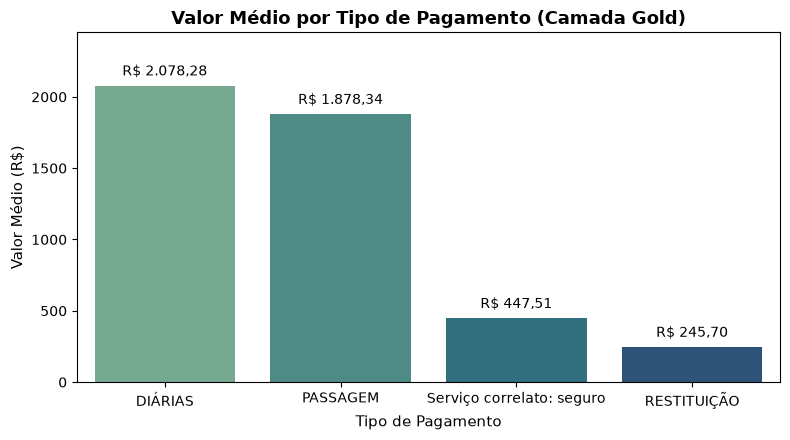

In [13]:
# --- Pergunta 4: Qual o tipo de pagamento com maior valor médio? (Camada Gold) ---

# 1. Consulta SQL usando os nomes reais das colunas da tabela Gold (valor_total_pago e total_lancamentos)
query_p4 = """
SELECT 
    tipo_pagamento,
    SUM(total_lancamentos)::INT AS total_lancamentos,
    ROUND(SUM(valor_total_pago), 2) AS valor_total,
    ROUND(SUM(valor_total_pago) / SUM(total_lancamentos), 2) AS media_valor
FROM gold_pagamento_resumo
WHERE tipo_pagamento IS NOT NULL
GROUP BY tipo_pagamento
ORDER BY media_valor DESC;
"""

df_p4 = consultar(query_p4)
display(df_p4)

# 2. Gráfico de Colunas sem avisos de depreciação
plt.figure(figsize=(8, 4.5))

ax = sns.barplot(
    data=df_p4, 
    x="tipo_pagamento", 
    y="media_valor", 
    hue="tipo_pagamento", 
    palette="crest", 
    legend=False
)

plt.title("Valor Médio por Tipo de Pagamento (Camada Gold)", fontsize=13, weight="bold")
plt.xlabel("Tipo de Pagamento", fontsize=11)
plt.ylabel("Valor Médio (R$)", fontsize=11)

# Rótulo com o valor monetário sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(
            f"R$ {altura:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."),
            (p.get_x() + p.get_width() / 2.0, altura),
            va="bottom",
            ha="center",
            xytext=(0, 5),
            textcoords="offset points",
            fontsize=10
        )

# Margem no topo para o texto não encostar na borda
max_media = df_p4["media_valor"].max()
if pd.notna(max_media) and max_media > 0:
    plt.ylim(0, max_media * 1.18)

plt.tight_layout()
plt.show()



## Conclusão

A consolidação na Camada Gold demonstra que DIÁRIAS e PASSAGEM respondem pelos maiores valores médios unitários do serviço público federal, superando com folga despesas de seguro e restituições. O tíquete médio mais elevado em diárias reflete o acúmulo de pernoites e custos de subsistência em missões prolongadas, enquanto as passagens sofrem forte influência de compras de última hora e trajetos aéreos de longa distância. Para a gestão orçamentária, medidas de controle no tempo de permanência em trânsito e políticas de compra antecipada de bilhetes representam as principais alavancas de economia.

### Pergunta 5: Qual o meio de transporte mais usado nos trechos?

,meio_transporte,total_trechos
0,Veículo Oficial,384783
1,Aéreo,215770
2,Rodoviário,64041
3,Veículo Próprio,42455
4,Inválido,25193
5,Fluvial,8388
6,Marítimo,451
7,Ferroviário,299


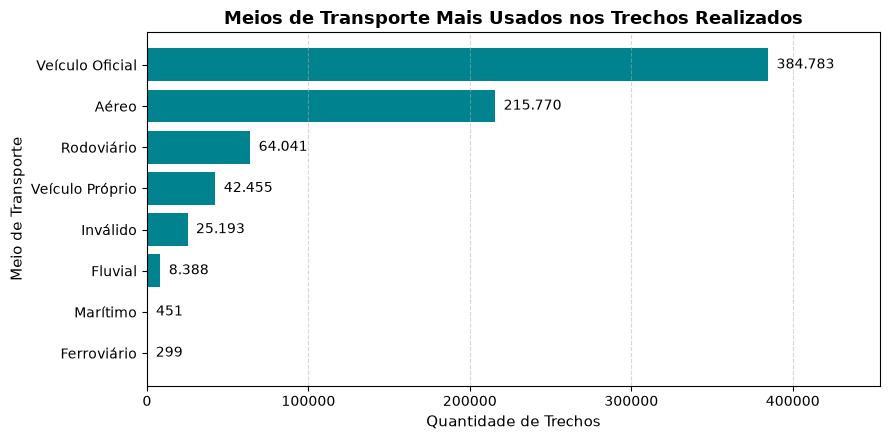

In [9]:
# --- Pergunta 5: Meios de Transporte Mais Usados (Camada Gold) ---
query_p5 = """
SELECT 
    meio_transporte,
    SUM(qtd_trechos)::INT AS total_trechos
FROM gold_trecho_resumo
GROUP BY meio_transporte
ORDER BY total_trechos DESC;
"""

df_p5 = consultar(query_p5)
display(df_p5)

# Gráfico
plt.figure(figsize=(9, 4.5))
df_plot = df_p5.iloc[::-1]

barras = plt.barh(df_plot["meio_transporte"], df_plot["total_trechos"], color="#00838F")
plt.title("Meios de Transporte Mais Usados nos Trechos Realizados", fontsize=13, weight="bold")
plt.xlabel("Quantidade de Trechos", fontsize=11)
plt.ylabel("Meio de Transporte", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.5)

for b in barras:
    w = b.get_width()
    if w > 0:
        plt.annotate(
            f"{int(w):,}".replace(",", "."),
            (w, b.get_y() + b.get_height() / 2.0),
            va="center", ha="left", xytext=(6, 0), textcoords="offset points", fontsize=10
        )

plt.xlim(0, df_p5["total_trechos"].max() * 1.18)
plt.tight_layout()
plt.show()

## Conclusão

A distribuição dos trechos das viagens realizadas revela que o transporte rodoviário governamental (Veículo Oficial) lidera com ampla margem a logística operacional do Governo Federal, superando o modal Aéreo em volume absoluto de deslocamentos. Essa configuração reflete a rotina descentralizada dos servidores públicos em fiscalizações de campo, vistorias técnicas e atendimentos itinerantes regionais, nos quais o uso de frotas oficiais e veículos próprios garante maior capilaridade geográfica do que a malha aeroviária comercial. A ocorrência de trechos classificados como "Inválido" aponta ainda a necessidade de aprimoramento nas regras de validação cadastral nos sistemas de origem do Portal da Transparência

### Pergunta 6: Qual UF de destino aparece em mais trechos?

,destino_uf,total_trechos
0,São Paulo,81727
1,Distrito Federal,77962
2,Minas Gerais,50555
3,Rio de Janeiro,43481
4,Paraná,42323
5,Pará,39742
6,Rio Grande do Sul,38397
7,Mato Grosso do Sul,30450
8,Bahia,28141
9,Pernambuco,28117


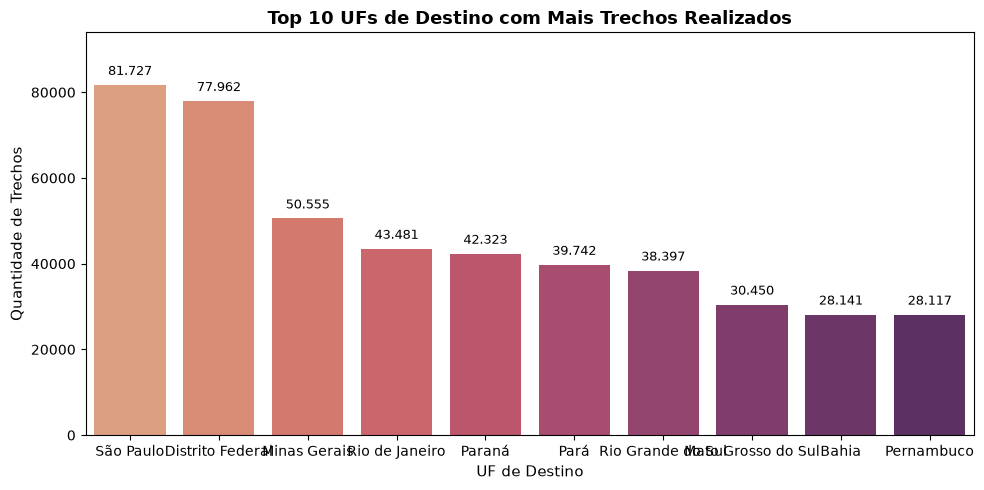

In [10]:
# --- Pergunta 6: Top 10 UFs de destino nos trechos realizados (Camada Gold) ---

query_p6 = """
SELECT 
    destino_uf,
    SUM(qtd_trechos)::INT AS total_trechos
FROM gold_trecho_resumo
WHERE destino_uf IS NOT NULL 
  AND TRIM(destino_uf) != ''
GROUP BY destino_uf
ORDER BY total_trechos DESC
LIMIT 10;
"""

df_p6 = consultar(query_p6)
display(df_p6)

# Gráfico de Colunas
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=df_p6,
    x="destino_uf",
    y="total_trechos",
    hue="destino_uf",
    palette="flare",
    legend=False
)

plt.title("Top 10 UFs de Destino com Mais Trechos Realizados", fontsize=13, weight="bold")
plt.xlabel("UF de Destino", fontsize=11)
plt.ylabel("Quantidade de Trechos", fontsize=11)

# Rótulos sobre as colunas
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(
            f"{int(altura):,}".replace(",", "."),
            (p.get_x() + p.get_width() / 2.0, altura),
            va="bottom",
            ha="center",
            xytext=(0, 5),
            textcoords="offset points",
            fontsize=9
        )

# Proteção de limite do eixo Y contra NaN
max_uf = df_p6["total_trechos"].max()
if pd.notna(max_uf) and max_uf > 0:
    plt.ylim(0, max_uf * 1.15)

plt.tight_layout()
plt.show()

## Conclusão

A agregação da Camada Gold demonstra uma forte concentração logística no eixo institucional e económico do país, liderado de forma muito próxima por São Paulo e Distrito Federal, ambos a aproximar-se dos 80 mil trechos. Enquanto Brasília representa o núcleo administrativo de deliberação política, estados como São Paulo, Minas Gerais e Rio de Janeiro concentram a maior parte das deslocações operacionais, fiscais e académicas. A presença expressiva de estados das regiões Norte, Sul, Nordeste e Centro-Oeste no Top 10 confirma a capilaridade da atuação governamental em fiscalizações ambientais, operações fronteiriças e políticas públicas regionais.

### Pergunta 7: Qual órgão pagou mais no total?

,nome_orgao_superior,total_pago
0,Ministério da Justiça e Segurança Pública,291022404.14
1,Sigiloso,200484801.68
2,Ministério da Defesa,156419344.46
3,Ministério da Educação,112342438.78
4,Ministério do Meio Ambiente e Mudança do Clima,49809487.63


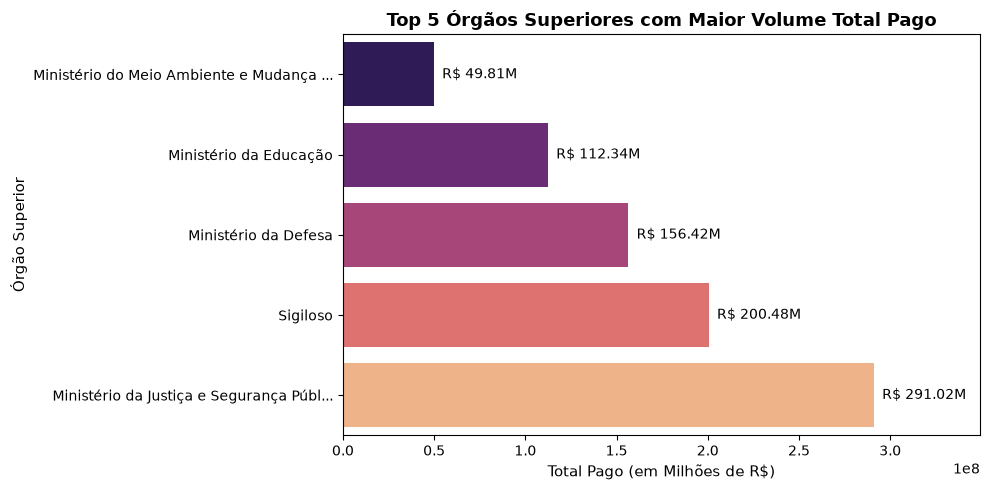

In [14]:
# --- Pergunta 7: Top 5 Órgãos Superiores com Maior Desembolso Total (Camada Gold) ---

query_p7 = """
SELECT 
    nome_orgao_superior,
    ROUND(SUM(valor_total_pago), 2) AS total_pago
FROM gold_pagamento_resumo
WHERE nome_orgao_superior IS NOT NULL 
  AND TRIM(nome_orgao_superior) != ''
GROUP BY nome_orgao_superior
ORDER BY total_pago DESC
LIMIT 5;
"""

df_p7 = consultar(query_p7)
display(df_p7)

if df_p7.empty or df_p7["total_pago"].isna().all():
    print("Aviso: A consulta não retornou registros para plotar o gráfico.")
else:
    df_p7["total_pago"] = pd.to_numeric(df_p7["total_pago"], errors="coerce").fillna(0)

    plt.figure(figsize=(10, 5))
    df_plot_p7 = df_p7.iloc[::-1].copy()

    # Encurta nomes muito longos para não cortar o layout
    df_plot_p7["rotulo_orgao"] = df_plot_p7["nome_orgao_superior"].apply(
        lambda x: str(x)[:38] + "..." if len(str(x)) > 38 else str(x)
    )

    ax = sns.barplot(
        data=df_plot_p7,
        x="total_pago",
        y="rotulo_orgao",
        hue="rotulo_orgao",
        palette="magma",
        legend=False
    )

    plt.title("Top 5 Órgãos Superiores com Maior Volume Total Pago", fontsize=13, weight="bold")
    plt.xlabel("Total Pago (em Milhões de R$)", fontsize=11)
    plt.ylabel("Órgão Superior", fontsize=11)

    # Rótulo em milhões de reais (R$ XX.XXM)
    for p in ax.patches:
        largura = p.get_width()
        if largura > 0:
            ax.annotate(
                f"R$ {largura / 1e6:.2f}M",
                (largura, p.get_y() + p.get_height() / 2.0),
                va="center",
                ha="left",
                xytext=(6, 0),
                textcoords="offset points",
                fontsize=10
            )

    # Limite seguro contra NaN e Inf
    max_val_p7 = df_p7["total_pago"].max()
    if pd.notna(max_val_p7) and max_val_p7 > 0:
        plt.xlim(0, max_val_p7 * 1.20)

    plt.tight_layout()
    plt.show()

    

## Conclusão

A agregação da Camada Gold confirma que o Ministério da Justiça e Segurança Pública assume a liderança orçamentária isolada nos desembolsos de viagens e diárias, acompanhado de perto pelas despesas classificadas sob a rubrica Sigiloso e pelo Ministério da Defesa. Este panorama evidencia a elevada concentração de recursos em missões de segurança, inteligência e operações táticas de Estado, cuja natureza ostensiva ou reservada impõe deslocamentos frequentes e continuados de efetivo. A presença do Ministério da Educação e do Meio Ambiente no grupo principal reforça a amplitude geográfica das ações de campo na fiscalização territorial e no intercâmbio da rede universitária e tecnológica federal em todo o país.